# Outside-Class Project: System Identification of a Forced Mass-Spring-Damper System

## 1. Problem Statement

We consider a laboratory-scale forced mass-spring-damper system governed by

$$
m\ddot{x} + c\dot{x} + kx = F_0\sin(\omega t)
$$

where

- $m$ = mass,
- $c$ = damping coefficient,
- $k$ = spring stiffness,
- $F_0$ = forcing amplitude,
- $\omega$ = forcing angular frequency,
- $x(t)$ = displacement.

The goal of this project is to use **optimization to recover unknown physical parameters and the initial state from measured displacement data**.

The parameter vector is

$$
\theta =
\begin{bmatrix}
m\\
c\\
k\\
x_0\\
v_0
\end{bmatrix}.
$$

Therefore, we will attempt to estimate

$$
m,\quad c,\quad k,\quad x_0,\quad v_0.
$$

The applied forcing is assumed to be known:

$$
F_0 = 5\ \text{N},
\qquad
f = 1.2\ \text{Hz},
\qquad
\omega = 2\pi f.
$$

The true values used to generate the synthetic observations are

| Parameter | True value | Unit |
|---|---:|---|
| Mass, $m$ | 10 | kg |
| Damping, $c$ | 20 | N·s/m |
| Stiffness, $k$ | 1000 | N/m |
| Initial displacement, $x_0$ | 0.02 | m |
| Initial velocity, $v_0$ | 0 | m/s |

These are **realistic synthetic values inspired by laboratory vibration systems**. They are not measurements from a specific commercial apparatus.

For reference, the undamped natural frequency is

$$
f_n =
\frac{1}{2\pi}\sqrt{\frac{k}{m}}
\approx 1.59\ \text{Hz},
$$

and the damping ratio is

$$
\zeta =
\frac{c}{2\sqrt{km}}
=0.10.
$$

In the clean synthetic-data case, $x_0$ is closely related to the first displacement observation. We still include it as an optimization variable so that the framework is ready for later experiments with measurement noise or uncertain initial conditions.

The inverse-problem workflow is

$$
\text{guess } \theta
\rightarrow
\text{solve the ODE}
\rightarrow
x_{\mathrm{sim}}(t;\theta)
\rightarrow
\text{compare with }x_{\mathrm{obs}}(t)
\rightarrow
J(\theta)
\rightarrow
\text{update } \theta.
$$


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import time
from scipy.integrate import solve_ivp

# Count calls to the ODE solver during each optimization method.
ode_solve_count = 0

# ---------------------------------------------------------
# True synthetic physical parameters
# These values are used only to generate the observed data.
# ---------------------------------------------------------

m_true = 10.0       # mass [kg]
c_true = 20.0       # damping coefficient [N*s/m]
k_true = 1000.0     # spring stiffness [N/m]

F0 = 5.0            # known forcing amplitude [N]
f = 1.2             # known forcing frequency [Hz]
omega = 2 * np.pi * f

x0_true = 0.02      # initial displacement [m]
v0_true = 0.0       # initial velocity [m/s]

t_start = 0.0
t_end = 10.0
t = np.linspace(t_start, t_end, 201)


## 2. Convert the ODE to First-Order Form

`solve_ivp` solves first-order differential equations, so we introduce velocity

$$
v = \dot{x}.
$$

The second-order equation

$$
m\ddot{x}+c\dot{x}+kx=F_0\sin(\omega t)
$$

becomes

$$
\dot{x}=v
$$

and

$$
\dot{v}
=
\frac{F_0\sin(\omega t)-cv-kx}{m}.
$$

The state vector is therefore

$$
y=
\begin{bmatrix}
x\\
v
\end{bmatrix}.
$$


In [2]:
def simulate_system(m_value, c_value, k_value, x0_value, v0_value):
    """Simulate displacement and velocity for one parameter set."""
    global ode_solve_count

    values = np.array([m_value, c_value, k_value, x0_value, v0_value])
    if not np.all(np.isfinite(values)) or m_value <= 0 or c_value < 0 or k_value <= 0:
        raise ValueError("Parameters must be finite, with m > 0, c >= 0, k > 0.")

    def oscillator(t_value, y):
        x = y[0]
        v = y[1]

        dxdt = v
        dvdt = (
            F0 * np.sin(omega * t_value)
            - c_value * v
            - k_value * x
        ) / m_value

        return [dxdt, dvdt]

    ode_solve_count += 1
    solution = solve_ivp(
        oscillator,
        [t_start, t_end],
        [x0_value, v0_value],
        t_eval=t,
        rtol=1e-9,
        atol=1e-11
    )

    if not solution.success or solution.y.shape != (2, len(t)) or not np.all(np.isfinite(solution.y)):
        raise RuntimeError("ODE integration failed: " + solution.message)

    x_sim = solution.y[0]
    v_sim = solution.y[1]

    return x_sim, v_sim

## 3. Solve the Forward Problem

Before solving the inverse problem, we need a **forward model**.

For any proposed parameter set

$$
(m,c,k,x_0,v_0),
$$

the function `simulate_system(...)` solves the governing ODE and returns

$$
x_{\mathrm{sim}}(t)
$$

and

$$
v_{\mathrm{sim}}(t).
$$

First, we run the forward model using the true synthetic parameters. This produces the motion that will later be treated as our measured data.


In [3]:
x, v = simulate_system(
    m_true,
    c_true,
    k_true,
    x0_true,
    v0_true
)


## 4. Displacement and Velocity

The forward solver returns the displacement and velocity histories:

$$
x(t)
$$

and

$$
v(t).
$$

For the inverse problem, we will assume that **displacement is measured**, while velocity does not have to be directly measured.


In [4]:
print("Number of time samples:", len(t))
print("Initial displacement:", x[0], "m")
print("Initial velocity:", v[0], "m/s")


Number of time samples: 201
Initial displacement: 0.02 m
Initial velocity: 0.0 m/s


## 5. Visualize the Synthetic Motion

The displacement response contains information about the physical parameters.

The transient part of the response is influenced strongly by the initial conditions and damping, while the later forced response depends on the mass, damping, stiffness, and forcing frequency.

We first visualize the true displacement before creating the synthetic observed data.


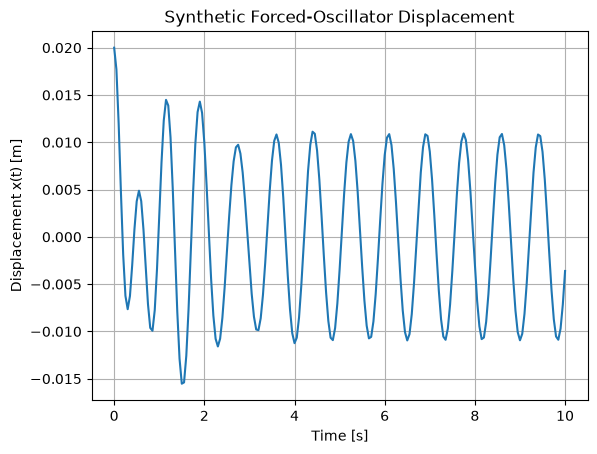

In [5]:
plt.plot(t, x)

plt.xlabel("Time [s]")
plt.ylabel("Displacement x(t) [m]")
plt.title("Synthetic Forced-Oscillator Displacement")

plt.grid(True)
plt.show()


## 6. Create Synthetic Observed Data

We now treat the simulated displacement as experimental observations:

$$
x_{\mathrm{obs}}(t)=x_{\mathrm{true}}(t).
$$

In a real experiment, this could come from a displacement sensor, camera, or motion-tracking system.

For now, we use clean synthetic data without measurement noise. This lets us first test whether the optimization methods can recover the known parameters under ideal conditions.

Later, measurement noise can be added as a more realistic experiment.


In [6]:
x_obs = x.copy()
x_scale = max(float(np.max(np.abs(x_obs))), np.finfo(float).eps)

print("Displacement scale =", x_scale)

Displacement scale = 0.02


## 7. Define the Unknown Parameter Vector

We now pretend that the following quantities are unknown:

$$
m,\quad c,\quad k,\quad x_0,\quad v_0.
$$

The optimization variable is

$$
\theta =
\begin{bmatrix}
m\\
c\\
k\\
x_0\\
v_0
\end{bmatrix}.
$$

For any proposed $\theta$, we solve the forward model and obtain a predicted displacement

$$
x_{\mathrm{sim}}(t;\theta).
$$

We compare that prediction with the observed displacement $x_{\mathrm{obs}}(t)$ using normalized residuals

$$
r_i =
\frac{
x_{\mathrm{sim}}(t_i;\theta)
-
x_{\mathrm{obs}}(t_i)
}{
x_{\mathrm{scale}}
}
$$

and the mean squared error

$$
J(\theta)
=
\frac{1}{N}
\sum_{i=1}^{N}
r_i^2.
$$

The inverse problem is therefore

$$
\boxed{
\min_{\theta} J(\theta)
}
$$


Initial parameter guess:
[8.e+00 3.e+01 8.e+02 3.e-02 5.e-02]


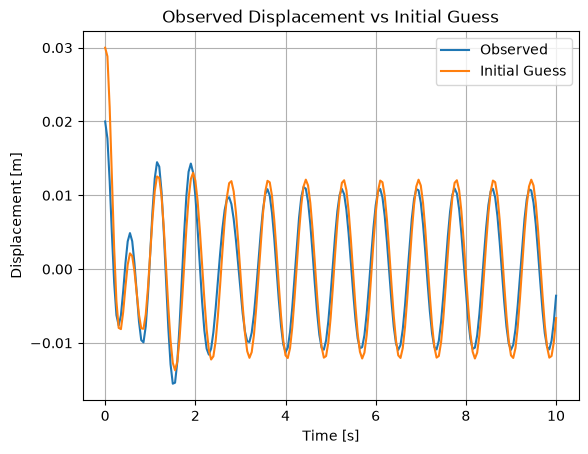

In [7]:
# Initial guess for all unknown parameters

m_guess = 8.0
c_guess = 30.0
k_guess = 800.0
x0_guess = 0.03
v0_guess = 0.05

theta_guess = np.array([
    m_guess,
    c_guess,
    k_guess,
    x0_guess,
    v0_guess
])

x_guess, v_guess = simulate_system(
    m_guess,
    c_guess,
    k_guess,
    x0_guess,
    v0_guess
)

print("Initial parameter guess:")
print(theta_guess)

plt.plot(t, x_obs, label="Observed")
plt.plot(t, x_guess, label="Initial Guess")

plt.xlabel("Time [s]")
plt.ylabel("Displacement [m]")
plt.title("Observed Displacement vs Initial Guess")

plt.legend()
plt.grid(True)
plt.show()


## 8. Define the Objective Function

The objective function receives one candidate parameter vector

$$
\theta=[m,c,k,x_0,v_0]
$$

and performs three operations:

1. simulate the mass-spring-damper system,
2. calculate the normalized displacement residual,

$$
r_i =
\frac{
x_{\mathrm{sim}}(t_i;\theta)
-
x_{\mathrm{obs}}(t_i)
}{
x_{\mathrm{scale}}
},
$$

3. calculate the mean squared error,

$$
J(\theta)
=
\frac{1}{N}\sum_{i=1}^{N}r_i^2.
$$

The displacement scale is chosen as

$$
x_{\mathrm{scale}}=\max_i |x_{\mathrm{obs}}(t_i)|.
$$

This normalization keeps the objective and its derivatives at numerically useful magnitudes.

A smaller objective value means that the simulated motion agrees more closely with the observed motion.


In [8]:
def objective(theta):

    m_value = theta[0]
    c_value = theta[1]
    k_value = theta[2]
    x0_value = theta[3]
    v0_value = theta[4]

    # Physical guard: mass and stiffness must remain positive
    if not np.all(np.isfinite(theta)) or m_value <= 0 or c_value < 0 or k_value <= 0:
        return np.inf

    x_sim, _ = simulate_system(
        m_value,
        c_value,
        k_value,
        x0_value,
        v0_value
    )

    residual = (x_sim - x_obs)/x_scale
    mse = np.mean(residual**2)

    return mse


theta_true = np.array([
    m_true,
    c_true,
    k_true,
    x0_true,
    v0_true
])

print("Objective at initial guess =", objective(theta_guess))
print("Objective at true parameters =", objective(theta_true))

Objective at initial guess = 0.0178438197991941
Objective at true parameters = 0.0


## 9. Scale the Optimization Variables

The unknown parameters have very different numerical magnitudes:

$$
m\sim10,\qquad
c\sim20,\qquad
k\sim1000,\qquad
x_0\sim0.02,\qquad
v_0\sim0.05.
$$

Using the same gradient-descent step size directly on all five physical
parameters can therefore lead to poorly balanced updates.

We introduce scaled variables

$$
z =
\begin{bmatrix}
z_m\\
z_c\\
z_k\\
z_{x_0}\\
z_{v_0}
\end{bmatrix}
$$

and define

$$
\theta = z \odot s,
$$

where the scale vector is the component-wise absolute value of the initial guess:

$$
s=|\theta_{\mathrm{guess}}|=
\begin{bmatrix}
8\\
30\\
800\\
0.03\\
0.05
\end{bmatrix}.
$$

If a component of the initial guess is zero, its scale is set to 1 so that
$z$ remains well defined.

The optimizer will work with $z$, while the ODE solver will continue
using the physical parameters $m,c,k,x_0,v_0$.

In [9]:
# A zero initial guess would give a zero scale, so use 1 for that component.
parameter_scale = np.where(theta_guess != 0, np.abs(theta_guess), 1.0)

z_guess = theta_guess / parameter_scale
z_true = theta_true / parameter_scale

print("Scaled initial guess =", z_guess)
print("Scaled true values   =", z_true)

Scaled initial guess = [1. 1. 1. 1. 1.]
Scaled true values   = [1.25       0.66666667 1.25       0.66666667 0.        ]


## 10. Define the Objective Function in Scaled Variables

The optimizer will work with the scaled parameter vector

$$
z =
\begin{bmatrix}
z_m\\
z_c\\
z_k\\
z_{x_0}\\
z_{v_0}
\end{bmatrix}.
$$

Before solving the ODE, the scaled variables are converted back to physical parameters:

$$
\theta = z \odot s.
$$

The physical parameter vector is

$$
\theta =
\begin{bmatrix}
m\\
c\\
k\\
x_0\\
v_0
\end{bmatrix}.
$$

The objective function remains

$$
J(z)
=
\frac{1}{N}
\sum_{i=1}^{N}
\left[
\frac{
x_{\mathrm{sim}}(t_i;z)
-
x_{\mathrm{obs}}(t_i)
}{
x_{\mathrm{scale}}
}
\right]^2.
$$

In [10]:
def scaled_objective(z):
    return objective(np.asarray(z, dtype=float) * parameter_scale)


print("Scaled objective at initial guess =", scaled_objective(z_guess))
print("Scaled objective at true values   =", scaled_objective(z_true))

Scaled objective at initial guess = 0.0178438197991941
Scaled objective at true values   = 0.0


## 11. Compute the Numerical Gradient

To use gradient descent, we need the gradient of the objective function with respect to the scaled variables:

$$
\nabla_z J =
\begin{bmatrix}
\frac{\partial J}{\partial z_m}\\
\frac{\partial J}{\partial z_c}\\
\frac{\partial J}{\partial z_k}\\
\frac{\partial J}{\partial z_{x_0}}\\
\frac{\partial J}{\partial z_{v_0}}
\end{bmatrix}.
$$

We approximate each derivative using a central finite difference:

$$
\frac{\partial J}{\partial z_i}
\approx
\frac{
J(z_i+h)-J(z_i-h)
}{
2h
}.
$$

Because the variables are scaled to be roughly order 1, the same finite-difference step size can be used for all five variables.

In [11]:
def numerical_gradient(z, h=1e-4):

    z = np.asarray(z, dtype=float)
    grad = np.zeros_like(z)

    for i in range(len(z)):

        z_plus = z.copy()
        z_minus = z.copy()

        z_plus[i] += h
        z_minus[i] -= h

        J_plus = scaled_objective(z_plus)
        J_minus = scaled_objective(z_minus)

        if np.isfinite(J_plus) and np.isfinite(J_minus):
            grad[i] = (J_plus - J_minus) / (2*h)
        elif np.isfinite(J_plus):
            grad[i] = (J_plus - scaled_objective(z)) / h
        elif np.isfinite(J_minus):
            grad[i] = (scaled_objective(z) - J_minus) / h
        else:
            raise ValueError("No finite finite-difference samples at this point.")

    return grad
    
# test
grad_initial = numerical_gradient(z_guess)

print("Gradient at initial guess:")
print(grad_initial)

Gradient at initial guess:
[ 0.1072508   0.0288375  -0.16905133  0.02033704  0.00368059]


## 12. Perform One Gradient Descent Step

Gradient descent updates the scaled parameter vector using

$$
z_{\text{new}}
=
z_{\text{old}}
-
\alpha \nabla_z J
$$

where $\alpha$ is the learning rate.

After the update, we compare the old and new objective values.

If

$$
J(z_{\text{new}}) < J(z_{\text{old}}),
$$

the step moved in a useful descent direction.

In [12]:
alpha = 0.1

J_old = scaled_objective(z_guess)

grad = numerical_gradient(z_guess)

z_new = z_guess - alpha * grad

J_new = scaled_objective(z_new)

print("Old scaled parameters:")
print(z_guess)

print("\nGradient:")
print(grad)

print("\nNew scaled parameters:")
print(z_new)

print("\nOld objective =", J_old)
print("New objective =", J_new)

Old scaled parameters:
[1. 1. 1. 1. 1.]

Gradient:
[ 0.1072508   0.0288375  -0.16905133  0.02033704  0.00368059]

New scaled parameters:
[0.98927492 0.99711625 1.01690513 0.9979663  0.99963194]

Old objective = 0.0178438197991941
New objective = 0.014277416136521047


## Backtracking Line Search

Gradient Descent, Newton's method, and BFGS use the same backtracking line search.
Each method supplies a search direction $p$ and begins with a step size
$\alpha=1$.

The step is accepted when the Armijo condition is satisfied:

$$
\boxed{
J(z+\alpha p)
\le
J(z)+c_1\alpha\nabla J(z)^T p
}
$$

Here $p$ is a descent direction, so $\nabla J(z)^T p<0$. If the condition is
not satisfied, the step size is reduced:

$$
\alpha \leftarrow \rho\alpha,
$$

where $\rho=0.5$.


In [13]:
def backtracking_direction(z, grad, p, alpha_start=1.0, rho=0.5, c1=1e-4):
    """Return an accepted Armijo step, or zero when no step is accepted."""
    slope = float(np.dot(grad, p))
    J_current = scaled_objective(z)
    if not np.isfinite(J_current) or not np.isfinite(slope) or slope >= 0:
        return 0.0
    alpha = alpha_start
    for _ in range(40):
        J_trial = scaled_objective(z + alpha * p)
        if np.isfinite(J_trial) and J_trial <= J_current + c1 * alpha * slope:
            return alpha
        alpha *= rho
    return 0.0


def backtracking_line_search(z, grad, alpha_start=1.0, rho=0.5, c1=1e-4):
    return backtracking_direction(z, grad, -grad, alpha_start, rho, c1)

## 13. Run Gradient Descent for Multiple Iterations

A single gradient-descent step only changes the parameter estimate slightly.

We therefore repeat

$$
z_{k+1}
=
z_k-\alpha\nabla J(z_k)
$$

for multiple iterations.

At each iteration we store:

- the scaled parameter vector,
- the corresponding physical parameters,
- the objective function value.

This will allow us to examine the convergence of the optimization.
Histories include iteration zero (the initial guess). Each method uses a budget of 300 updates and stops when the gradient norm is below the tolerance or no acceptable step is found. Reaching the budget does not imply convergence.


In [14]:
tol = 1e-6
max_iterations = 300

In [15]:
ode_solve_count = 0
start_time = time.perf_counter()

z_current = z_guess.copy()

z_history = [z_guess.copy()]
theta_history = [theta_guess.copy()]
J_history = [scaled_objective(z_current)]
alpha_history = []
grad_history_gd = []
gd_status = "Maximum iterations reached"

for iteration in range(max_iterations):

    grad = numerical_gradient(z_current)

    grad_norm = np.linalg.norm(grad)
    grad_history_gd.append(grad_norm)

    if grad_norm < tol:
        gd_status = "Converged"
        print("Gradient Descent converged at iteration", iteration)
        break

    alpha = backtracking_line_search(
        z_current,
        grad
    )

    if alpha == 0:
        gd_status = "Line search failed"
        print("Gradient Descent stopped: no acceptable step.")
        break
    alpha_history.append(alpha)

    # Gradient descent update
    z_current = z_current - alpha * grad

    # Evaluate objective
    J = scaled_objective(z_current)

    # Convert back to physical parameters
    theta_current = z_current * parameter_scale

    # Store history
    z_history.append(z_current.copy())
    theta_history.append(theta_current.copy())
    J_history.append(J)

gd_ode_solves = ode_solve_count
gd_time = time.perf_counter() - start_time

z_history = np.array(z_history)
theta_history = np.array(theta_history)
J_history = np.array(J_history)
alpha_history = np.array(alpha_history)
grad_history_gd = np.array(grad_history_gd)

## 14. Visualize Gradient Descent Convergence

We now plot the objective function and all estimated parameters in a single figure.

This makes it easier to see how the optimization progresses and whether the estimated parameters approach their true values.

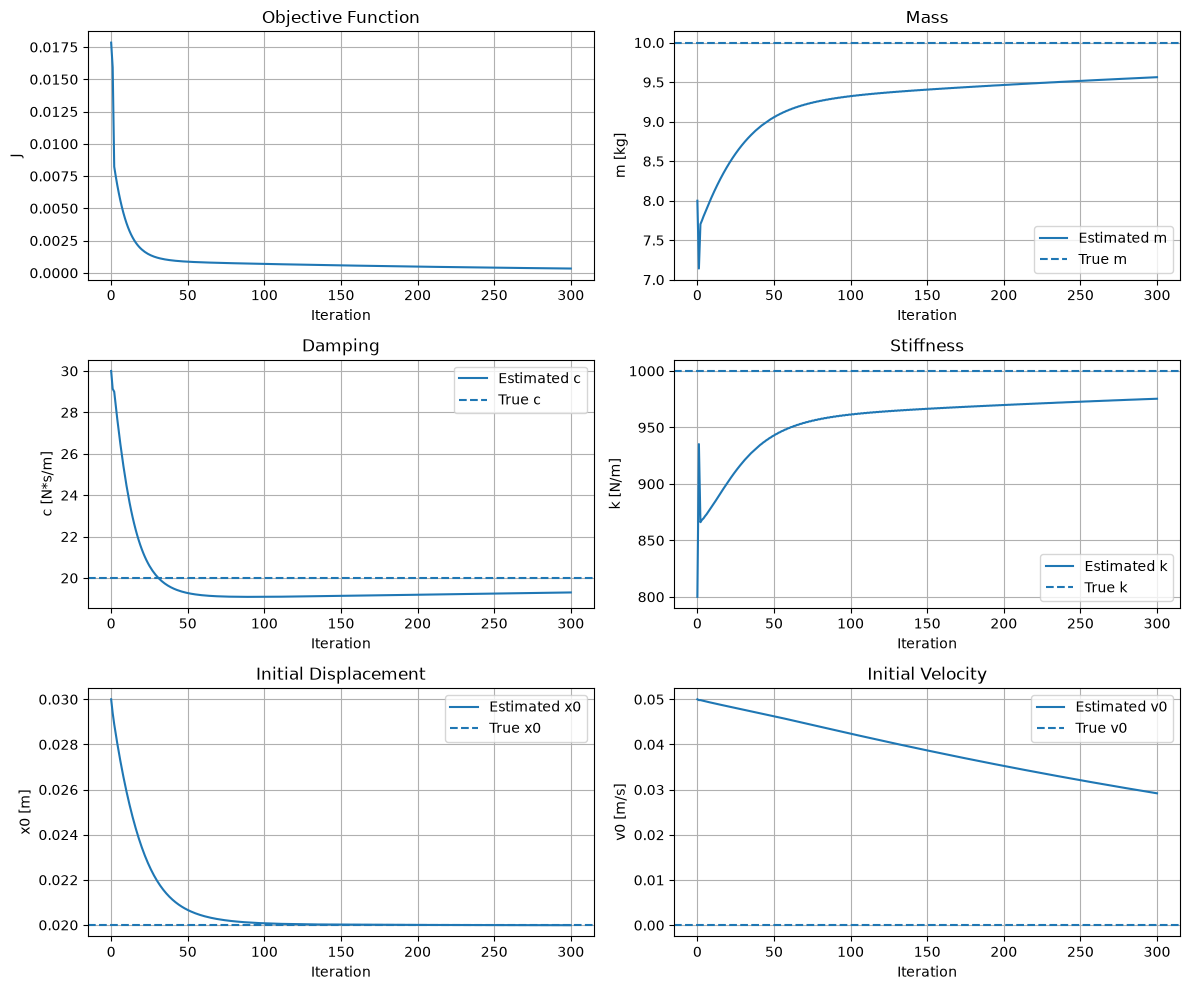

In [16]:
fig, axes = plt.subplots(3, 2, figsize=(12, 10))

# Objective
axes[0, 0].plot(J_history)
axes[0, 0].set_title("Objective Function")
axes[0, 0].set_xlabel("Iteration")
axes[0, 0].set_ylabel("J")
axes[0, 0].grid(True)

# Mass
axes[0, 1].plot(theta_history[:, 0], label="Estimated m")
axes[0, 1].axhline(m_true, linestyle="--", label="True m")
axes[0, 1].set_title("Mass")
axes[0, 1].set_xlabel("Iteration")
axes[0, 1].set_ylabel("m [kg]")
axes[0, 1].legend()
axes[0, 1].grid(True)

# Damping
axes[1, 0].plot(theta_history[:, 1], label="Estimated c")
axes[1, 0].axhline(c_true, linestyle="--", label="True c")
axes[1, 0].set_title("Damping")
axes[1, 0].set_xlabel("Iteration")
axes[1, 0].set_ylabel("c [N*s/m]")
axes[1, 0].legend()
axes[1, 0].grid(True)

# Stiffness
axes[1, 1].plot(theta_history[:, 2], label="Estimated k")
axes[1, 1].axhline(k_true, linestyle="--", label="True k")
axes[1, 1].set_title("Stiffness")
axes[1, 1].set_xlabel("Iteration")
axes[1, 1].set_ylabel("k [N/m]")
axes[1, 1].legend()
axes[1, 1].grid(True)

# Initial displacement
axes[2, 0].plot(theta_history[:, 3], label="Estimated x0")
axes[2, 0].axhline(x0_true, linestyle="--", label="True x0")
axes[2, 0].set_title("Initial Displacement")
axes[2, 0].set_xlabel("Iteration")
axes[2, 0].set_ylabel("x0 [m]")
axes[2, 0].legend()
axes[2, 0].grid(True)

# Initial velocity
axes[2, 1].plot(theta_history[:, 4], label="Estimated v0")
axes[2, 1].axhline(v0_true, linestyle="--", label="True v0")
axes[2, 1].set_title("Initial Velocity")
axes[2, 1].set_xlabel("Iteration")
axes[2, 1].set_ylabel("v0 [m/s]")
axes[2, 1].legend()
axes[2, 1].grid(True)

plt.tight_layout()
plt.show()

## 15. Newton's Method

Gradient descent uses only the gradient of the objective function.

Newton's method additionally uses the Hessian matrix,

$$
H(z)=\nabla^2 J(z),
$$

which contains information about the curvature of the objective function.

At each iteration, the Newton direction $p$ is obtained by solving

$$
H(z)p=-\nabla J(z).
$$

The parameters are then updated using

$$
z_{\mathrm{new}}=z+\alpha p,
$$

where $\alpha$ is determined using backtracking line search.

The same scaled objective function and initial parameter guess used for
gradient descent are also used for Newton's method.
If the Hessian is singular or its direction is not a descent direction, we use the negative gradient. A failed line search leaves the current estimate unchanged.


In [17]:
def numerical_hessian(z, h=1e-4):

    n = len(z)
    H = np.zeros((n, n))

    for i in range(n):
        for j in range(i, n):

            z_pp = z.copy()
            z_pm = z.copy()
            z_mp = z.copy()
            z_mm = z.copy()

            z_pp[i] += h
            z_pp[j] += h

            z_pm[i] += h
            z_pm[j] -= h

            z_mp[i] -= h
            z_mp[j] += h

            z_mm[i] -= h
            z_mm[j] -= h

            H[i, j] = (
                scaled_objective(z_pp)
                - scaled_objective(z_pm)
                - scaled_objective(z_mp)
                + scaled_objective(z_mm)
            ) / (4 * h**2)

            H[j, i] = H[i, j]

    return H


In [18]:
H_initial = numerical_hessian(z_guess)

print("Hessian at initial guess:")
print(H_initial)

Hessian at initial guess:
[[ 9.20303452e-01 -4.29023764e-02 -1.31711845e+00  6.58366486e-02
   1.65473558e-02]
 [-4.29023764e-02  5.80517820e-02  3.41817544e-02 -1.32170140e-02
  -1.00657590e-04]
 [-1.31711845e+00  3.41817544e-02  2.09778009e+00 -3.55631624e-02
  -1.47384283e-02]
 [ 6.58366486e-02 -1.32170140e-02 -3.55631624e-02  7.92941711e-02
   3.57332341e-03]
 [ 1.65473558e-02 -1.00657590e-04 -1.47384283e-02  3.57332341e-03
   1.65812294e-03]]


## 16. Compute the Newton Direction

Newton's direction is found from

$$
H p = -g
$$

where $g=\nabla J$ and $H=\nabla^2J$.

In [19]:
def newton_direction(z, grad):
    """Use Newton curvature only when it gives a finite descent direction."""
    H = numerical_hessian(z)
    try:
        p = np.linalg.solve(H, -grad)
    except np.linalg.LinAlgError:
        return -grad
    if not np.all(np.isfinite(p)) or np.dot(grad, p) >= 0:
        return -grad
    return p


grad = numerical_gradient(z_guess)
p_newton = newton_direction(z_guess, grad)
print("Gradient:", grad)
print("Safeguarded Newton direction:", p_newton)

Gradient: [ 0.1072508   0.0288375  -0.16905133  0.02033704  0.00368059]
Safeguarded Newton direction: [ 0.11507545 -0.57304151  0.14686179 -0.31803315 -1.41215108]


In [20]:
alpha = backtracking_direction(z_guess, grad, p_newton)

z_newton = z_guess + alpha * p_newton

print("Old objective =", scaled_objective(z_guess))
print("New objective =", scaled_objective(z_newton))

Old objective = 0.0178438197991941
New objective = 0.007957169438648529


In [21]:
ode_solve_count = 0
start_time = time.perf_counter()

z_current = z_guess.copy()
grad_history_newton = []

theta_history_newton = [theta_guess.copy()]
J_history_newton = [scaled_objective(z_current)]
newton_status = "Maximum iterations reached"

for iteration in range(max_iterations):

    grad = numerical_gradient(z_current)

    grad_norm = np.linalg.norm(grad)
    grad_history_newton.append(grad_norm)

    if grad_norm < tol:
        newton_status = "Converged"
        print("Newton converged at iteration", iteration)
        break

    p = newton_direction(z_current, grad)
    alpha = backtracking_direction(z_current, grad, p)
    if alpha == 0:
        newton_status = "Line search failed"
        print("Newton stopped: no acceptable step.")
        break

    # Update
    z_current = z_current + alpha * p

    theta_current = z_current * parameter_scale
    J = scaled_objective(z_current)

    theta_history_newton.append(theta_current.copy())
    J_history_newton.append(J)

newton_ode_solves = ode_solve_count
newton_time = time.perf_counter() - start_time


Newton converged at iteration 5


In [22]:
theta_history_newton = np.array(theta_history_newton)
J_history_newton = np.array(J_history_newton)
grad_history_newton = np.array(grad_history_newton)

## 17. Quasi-Newton Method (BFGS)

BFGS avoids computing the full Hessian directly.

It builds an approximation of the inverse Hessian and uses

$$
p_k=-B_k\nabla J(z_k).
$$

In [23]:
# All three methods use the shared safeguarded Armijo line search above.

In [24]:
ode_solve_count = 0
start_time = time.perf_counter()

z_current = z_guess.copy()

n = len(z_current)

# Initial inverse Hessian approximation
B = np.eye(n)


theta_history_bfgs = [theta_guess.copy()]
J_history_bfgs = [scaled_objective(z_current)]
grad_history_bfgs = []
grad = numerical_gradient(z_current)
bfgs_status = "Maximum iterations reached"

for iteration in range(max_iterations):

    grad_norm = np.linalg.norm(grad)
    grad_history_bfgs.append(grad_norm)

    if grad_norm < tol:
        bfgs_status = "Converged"
        print("BFGS converged at iteration", iteration)
        break


    # BFGS search direction
    p = -B @ grad
    if not np.all(np.isfinite(p)) or np.dot(grad, p) >= 0:
        B = np.eye(n)
        p = -grad

    # Line search
    alpha = backtracking_direction(
        z_current,
        grad,
        p
    )

    if alpha == 0:
        bfgs_status = "Line search failed"
        print("BFGS stopped: no acceptable step.")
        break

    # Update parameters
    z_new = z_current + alpha * p

    grad_new = numerical_gradient(z_new)

    # BFGS quantities
    s = z_new - z_current
    y = grad_new - grad

    ys = np.dot(y, s)

    # Update inverse Hessian approximation
    if ys > 1e-12:

        rho = 1.0 / ys

        I = np.eye(n)

        B = (
            (I - rho * np.outer(s, y))
            @ B
            @ (I - rho * np.outer(y, s))
            + rho * np.outer(s, s)
        )

    z_current = z_new
    grad = grad_new

    theta_current = z_current * parameter_scale
    J = scaled_objective(z_current)

    theta_history_bfgs.append(theta_current.copy())
    J_history_bfgs.append(J)

bfgs_ode_solves = ode_solve_count
bfgs_time = time.perf_counter() - start_time

# Convert the BFGS histories to arrays after the loop.
theta_history_bfgs = np.array(theta_history_bfgs)
J_history_bfgs = np.array(J_history_bfgs)
grad_history_bfgs = np.array(grad_history_bfgs)

BFGS converged at iteration 28


In [25]:
theta_gd = theta_history[-1].copy()
theta_newton = theta_history_newton[-1].copy()
theta_bfgs = theta_history_bfgs[-1].copy()


## 18. Compare the Three Optimization Methods

We compare Gradient Descent, Newton's Method, and BFGS using:

- objective value by iteration,
- gradient norm by iteration,
- number of iterations,
- number of calls to solve_ivp (this includes two re-evaluations of $J$ per iteration:
  one at the start of each line search and one after each accepted step),
- measured optimizer runtime,
- final estimated parameters and their errors.


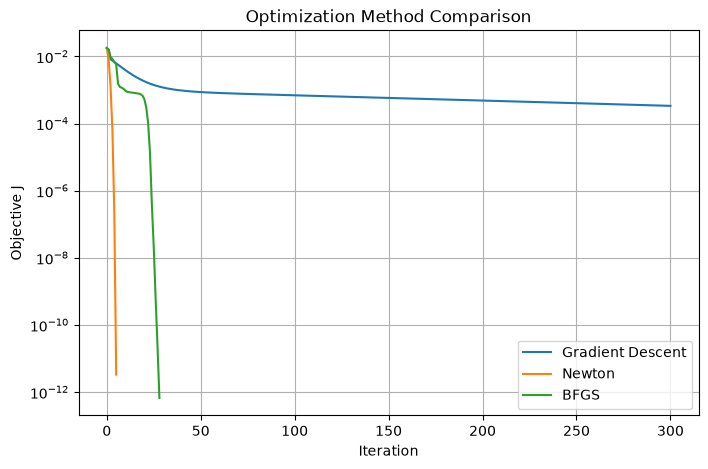

In [26]:
plt.figure(figsize=(8, 5))

plt.semilogy(J_history, label="Gradient Descent")
plt.semilogy(J_history_newton, label="Newton")
plt.semilogy(J_history_bfgs, label="BFGS")

plt.xlabel("Iteration")
plt.ylabel("Objective J")
plt.title("Optimization Method Comparison")

plt.legend()
plt.grid(True)
plt.show()

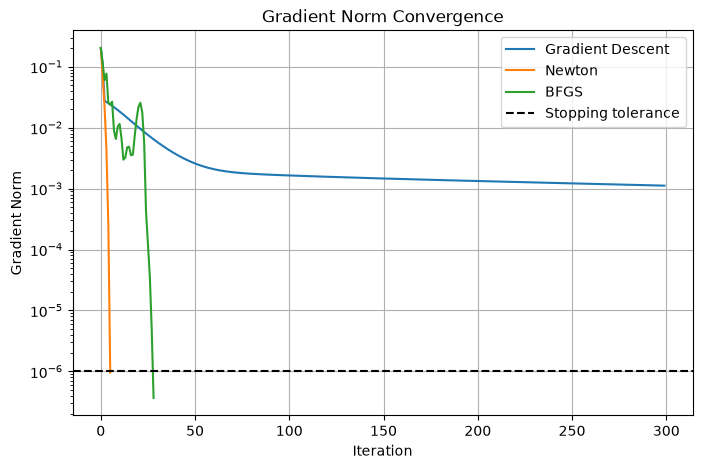

In [27]:
plt.figure(figsize=(8, 5))

plt.semilogy(grad_history_gd, label="Gradient Descent")
plt.semilogy(grad_history_newton, label="Newton")
plt.semilogy(grad_history_bfgs, label="BFGS")
plt.axhline(tol, linestyle="--", color="black", label="Stopping tolerance")

plt.xlabel("Iteration")
plt.ylabel("Gradient Norm")
plt.title("Gradient Norm Convergence")

plt.legend()
plt.grid(True)
plt.show()


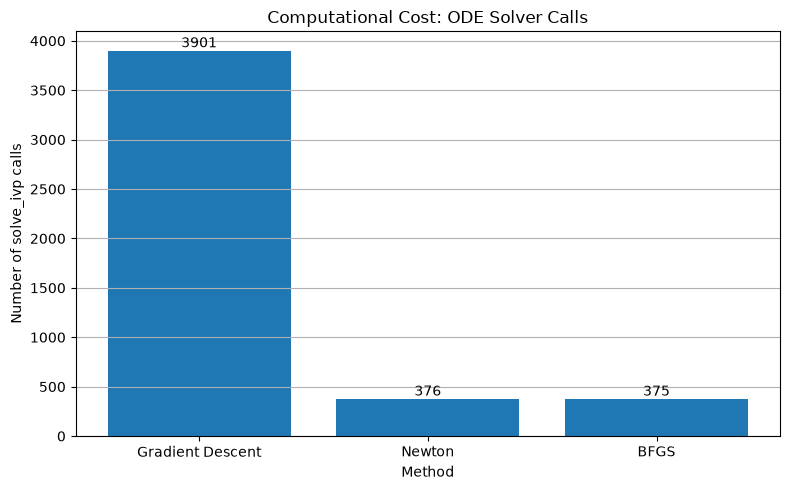

In [28]:
method_names = ["Gradient Descent", "Newton", "BFGS"]
ode_solve_counts = [gd_ode_solves, newton_ode_solves, bfgs_ode_solves]

plt.figure(figsize=(8, 5))
bars = plt.bar(method_names, ode_solve_counts)

plt.xlabel("Method")
plt.ylabel("Number of solve_ivp calls")
plt.title("Computational Cost: ODE Solver Calls")
plt.grid(axis="y")

for bar, count in zip(bars, ode_solve_counts):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        str(count),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()


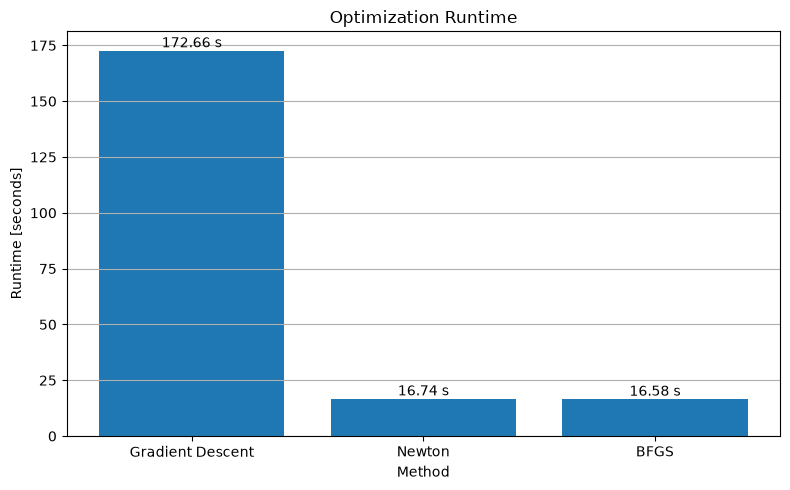

In [29]:
method_names = ["Gradient Descent", "Newton", "BFGS"]
method_times = [gd_time, newton_time, bfgs_time]

plt.figure(figsize=(8, 5))
bars = plt.bar(method_names, method_times)

plt.xlabel("Method")
plt.ylabel("Runtime [seconds]")
plt.title("Optimization Runtime")
plt.grid(axis="y")

for bar, value in zip(bars, method_times):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.2f} s",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()


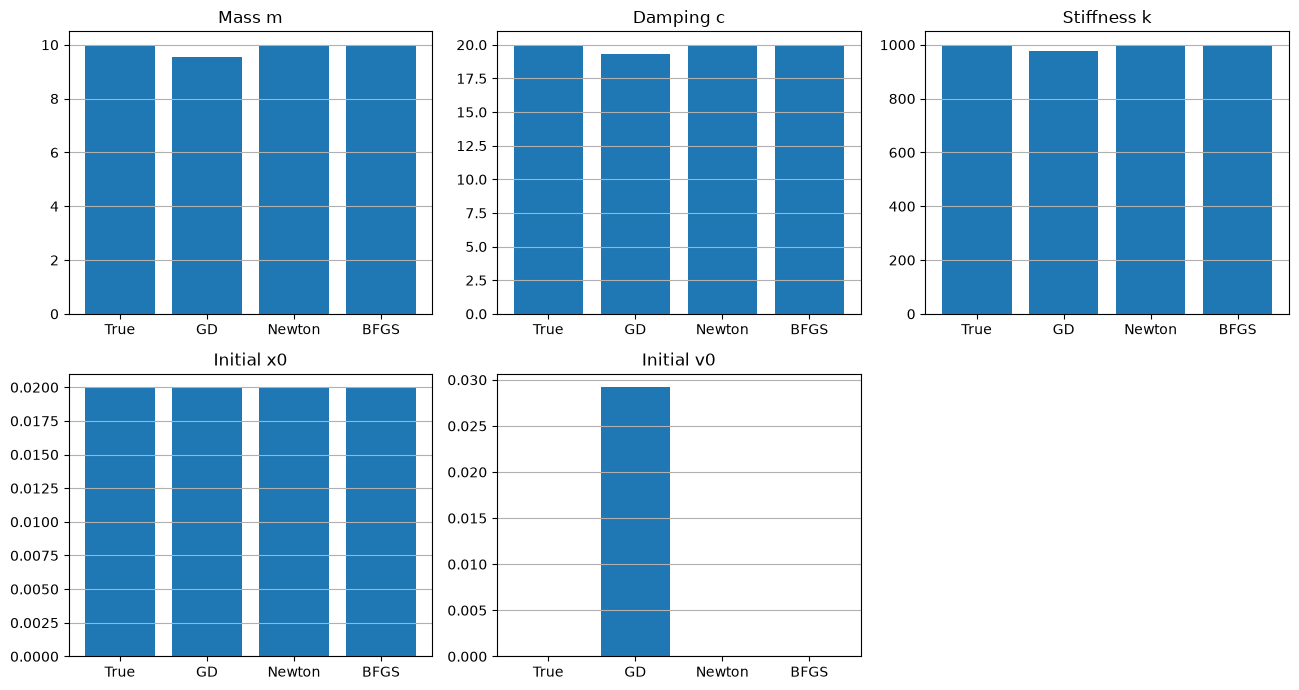

In [30]:
parameter_names = ["Mass m", "Damping c", "Stiffness k", "Initial x0", "Initial v0"]

true_values = theta_true
gd_values = theta_gd
newton_values = theta_newton
bfgs_values = theta_bfgs

fig, axes = plt.subplots(2, 3, figsize=(13, 7))

axes = axes.flatten()

for i in range(5):

    values = [
        true_values[i],
        gd_values[i],
        newton_values[i],
        bfgs_values[i]
    ]

    axes[i].bar(
        ["True", "GD", "Newton", "BFGS"],
        values
    )

    axes[i].set_title(parameter_names[i])
    axes[i].grid(axis="y")

# Remove unused sixth subplot
axes[5].axis("off")

plt.tight_layout()
plt.show()

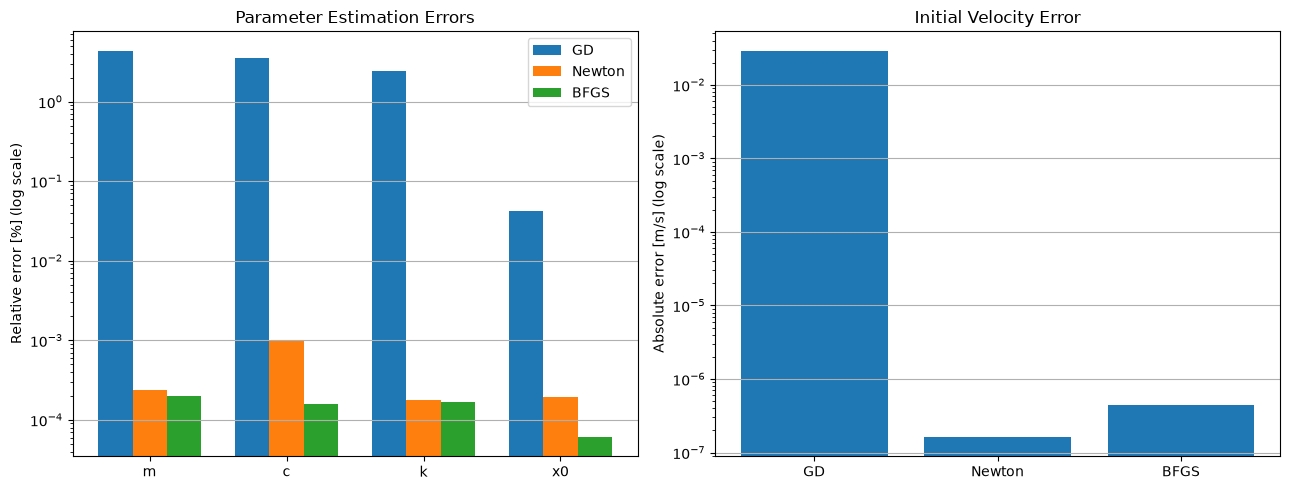

In [31]:
parameter_labels = ["m", "c", "k", "x0"]
true_parameters = theta_true[:4]

gd_percent_error = (
    np.abs(theta_gd[:4] - true_parameters)
    / np.abs(true_parameters)
    * 100
)
newton_percent_error = (
    np.abs(theta_newton[:4] - true_parameters)
    / np.abs(true_parameters)
    * 100
)
bfgs_percent_error = (
    np.abs(theta_bfgs[:4] - true_parameters)
    / np.abs(true_parameters)
    * 100
)

positions = np.arange(len(parameter_labels))
bar_width = 0.25

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].bar(positions - bar_width, gd_percent_error, bar_width, label="GD")
axes[0].bar(positions, newton_percent_error, bar_width, label="Newton")
axes[0].bar(positions + bar_width, bfgs_percent_error, bar_width, label="BFGS")
axes[0].set_xticks(positions)
axes[0].set_xticklabels(parameter_labels)
axes[0].set_yscale("log")
axes[0].set_ylabel("Relative error [%] (log scale)")
axes[0].set_title("Parameter Estimation Errors")
axes[0].legend()
axes[0].grid(axis="y")

v0_absolute_error = [
    abs(theta_gd[4] - theta_true[4]),
    abs(theta_newton[4] - theta_true[4]),
    abs(theta_bfgs[4] - theta_true[4])
]

axes[1].bar(["GD", "Newton", "BFGS"], v0_absolute_error)
axes[1].set_yscale("log")
axes[1].set_ylabel("Absolute error [m/s] (log scale)")
axes[1].set_title("Initial Velocity Error")
axes[1].grid(axis="y")

plt.tight_layout()
plt.show()


## 19. Compare the Final Fitted Responses

Using the final parameters from each optimization method, we simulate the system again and compare the predicted displacement with the observed displacement.

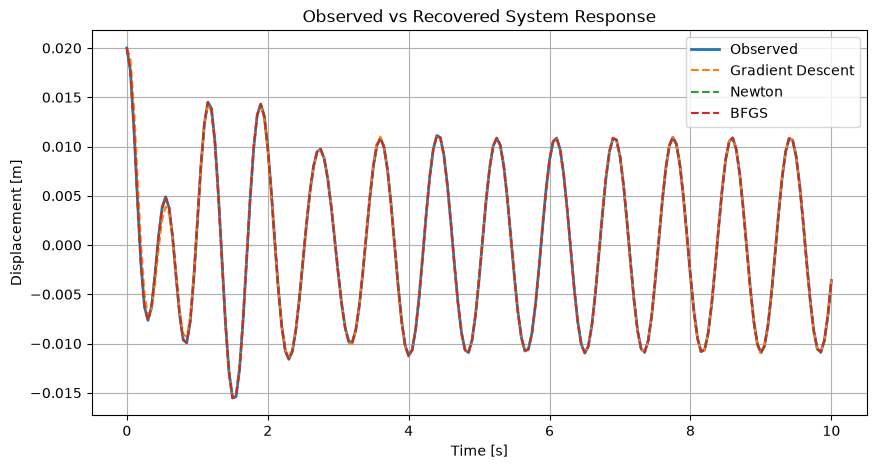

In [32]:
# Final parameter estimates

# Simulate using final estimates
x_gd, _ = simulate_system(*theta_gd)
x_newton, _ = simulate_system(*theta_newton)
x_bfgs, _ = simulate_system(*theta_bfgs)

# Plot
plt.figure(figsize=(10, 5))

plt.plot(t, x_obs, label="Observed", linewidth=2)
plt.plot(t, x_gd, "--", label="Gradient Descent")
plt.plot(t, x_newton, "--", label="Newton")
plt.plot(t, x_bfgs, "--", label="BFGS")

plt.xlabel("Time [s]")
plt.ylabel("Displacement [m]")
plt.title("Observed vs Recovered System Response")

plt.legend()
plt.grid(True)
plt.show()

## 20. Compare Parameter Estimation Error

The relative parameter error is calculated as

$$
\text{Error}(\%) =
\frac{|\theta_{\text{estimated}}-\theta_{\text{true}}|}
{|\theta_{\text{true}}|}
\times 100.
$$

For $v_0=0$, percentage error is not defined, so we report the absolute error instead.

In [33]:
parameter_names = ["m", "c", "k", "x0", "v0"]


methods = {
    "Gradient Descent": theta_gd,
    "Newton": theta_newton,
    "BFGS": theta_bfgs
}

for method, theta_est in methods.items():

    print("\n", method)

    for i, name in enumerate(parameter_names):

        if theta_true[i] != 0:

            error = (
                abs(theta_est[i] - theta_true[i])
                / abs(theta_true[i])
                * 100
            )

            print(name, "error =", error, "%")

        else:

            error = abs(theta_est[i] - theta_true[i])

            print(name, "absolute error =", error)


 Gradient Descent
m error = 4.373192042846679 %
c error = 3.4894169507873234 %
k error = 2.4588658529922327 %
x0 error = 0.04218931162877984 %
v0 absolute error = 0.02919363887150342

 Newton
m error = 0.0002378615398157535 %
c error = 0.0010217358239472674 %
k error = 0.00017593936440789547 %
x0 error = 0.00019521802535615862 %
v0 absolute error = 1.6449567915317182e-07

 BFGS
m error = 0.00019930374522303398 %
c error = 0.00015801796191539097 %
k error = 0.00016589387103067564 %
x0 error = 6.151529294631808e-05 %
v0 absolute error = 4.4632416478047205e-07


## 21. Summary of Optimization Results

The table compares each method's convergence status, iteration count,
solve_ivp calls, runtime, final objective value, and recovered parameters.
Runtime is for one notebook run and can vary with the computer and its current
workload.


In [34]:
print(
    f"{'Method':<20}"
    f"{'Status':<28}"
    f"{'Iterations':>12}"
    f"{'ODE solves':>13}"
    f"{'Time [s]':>11}"
    f"{'Final J':>15}"
    f"{'m':>12}"
    f"{'c':>12}"
    f"{'k':>12}"
    f"{'x0':>12}"
    f"{'v0':>12}"
)

print("-" * 159)

print(
    f"{'Gradient Descent':<20}"
    f"{gd_status:<28}"
    f"{(len(J_history) - 1):>12}"
    f"{gd_ode_solves:>13}"
    f"{gd_time:>11.2f}"
    f"{J_history[-1]:>15.3e}"
    f"{theta_gd[0]:>12.4f}"
    f"{theta_gd[1]:>12.4f}"
    f"{theta_gd[2]:>12.4f}"
    f"{theta_gd[3]:>12.6f}"
    f"{theta_gd[4]:>12.6f}"
)

print(
    f"{'Newton':<20}"
    f"{newton_status:<28}"
    f"{(len(J_history_newton) - 1):>12}"
    f"{newton_ode_solves:>13}"
    f"{newton_time:>11.2f}"
    f"{J_history_newton[-1]:>15.3e}"
    f"{theta_newton[0]:>12.4f}"
    f"{theta_newton[1]:>12.4f}"
    f"{theta_newton[2]:>12.4f}"
    f"{theta_newton[3]:>12.6f}"
    f"{theta_newton[4]:>12.6f}"
)

print(
    f"{'BFGS':<20}"
    f"{bfgs_status:<28}"
    f"{(len(J_history_bfgs) - 1):>12}"
    f"{bfgs_ode_solves:>13}"
    f"{bfgs_time:>11.2f}"
    f"{J_history_bfgs[-1]:>15.3e}"
    f"{theta_bfgs[0]:>12.4f}"
    f"{theta_bfgs[1]:>12.4f}"
    f"{theta_bfgs[2]:>12.4f}"
    f"{theta_bfgs[3]:>12.6f}"
    f"{theta_bfgs[4]:>12.6f}"
)


Method              Status                        Iterations   ODE solves   Time [s]        Final J           m           c           k          x0          v0
---------------------------------------------------------------------------------------------------------------------------------------------------------------
Gradient Descent    Maximum iterations reached           300         3901     172.66      3.369e-04      9.5627     19.3021    975.4113    0.019992    0.029194
Newton              Converged                              5          376      16.74      3.307e-12     10.0000     19.9998    999.9982    0.020000    0.000000
BFGS                Converged                             28          375      16.58      6.663e-13     10.0000     20.0000   1000.0017    0.020000    0.000000


## 22. Conclusions

**Newton and BFGS recover all five unknowns.** From the same initial guess, both
methods reach the gradient tolerance and recover $m$, $c$, $k$ and $x_0$ to within
0.002%, and $v_0$ to within $10^{-6}$ m/s. Newton needs only 5 iterations and BFGS
needs 28, but their costs are almost equal (376 and 375 calls to `solve_ivp`). Each
Newton iteration builds a finite-difference Hessian (60 ODE solves), while a BFGS
iteration only needs a gradient (10 ODE solves) and a line search.

**Gradient descent does not converge within the budget.** It uses all 300 iterations
and about ten times as many ODE solves (3901) and still stops at $J\approx3.4\times10^{-4}$,
with errors of 4.4% in $m$, 3.5% in $c$, 2.5% in $k$ and 0.029 m/s in $v_0$.
Only $x_0$ is recovered well (0.04%), because the first observation constrains it directly.


Gradient descent steps along the steep directions and makes slow progress along the
valley floor. Newton and BFGS use curvature information to rescale the step, which is
why they reach the minimum in a few iterations.

